In [2]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import multivariate_normal

from utils import plot_points

# Lecture 2: Variational approximation

* Variational lower bound
* Variational inference for mixture of Gaussians
* *Bonus: Variational multi-layer perceptron*

Bishop, **Chapter 10** and McKay, **Chapter 33**.

## Refresher on variational approximation of distributions: the case of a 2d Gaussian

Recall the definition of the **Relative entropy** or **Kullback-Leibler (KL) divergence**:

$$
\mathrm{KL}(p||q) = \sum_i p_i \log \left(\frac{ p_i} {q_i} \right)
$$

and for continuous variables:
$$ \mathrm{KL}(p||q) =  - \int p(\mathbf{x})\ln \left( \frac{ q(\mathbf{x})}{p(\mathbf{x})}  \right) d\mathbf{x}
$$

#### Properties:

- $\mathrm{KL}(p||q) \neq \mathrm{KL}(q||p) $ (not a distance)
- $\mathrm{KL}(p||q) \geq 0$, $\mathrm{KL}(p||q) = 0 \Leftrightarrow p = q$ (proof through Jensen's inequality)
- We need that when $q_i=0$ also $p_i=0$, otherwise $p_i \log \left(\frac{ p_i} {q_i} \right)$ is not defined. (The reverse is no problem: when $p_i=0$ and $q_i\ne 0$ we have $p_i \log \left(\frac{ p_i} {q_i} \right)=0$)

### Example: approximating an elongated Gaussian with an isotropic one

Consider $p$ a elongated Gaussian distribution in 2d. Approximate with the simpler factorized distribution $q(z_1,z_2)=q(z_1)q(z_2)$. 

You will notice that the variational approximation tends to under estimate the variance (variational approximations tend to be **compact**).

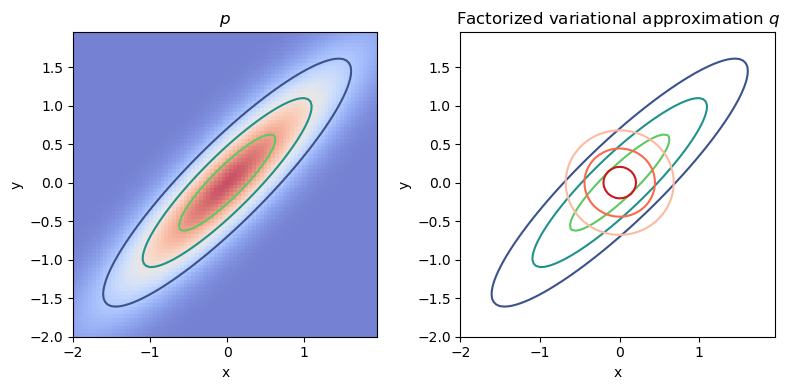

In [3]:
# define true multivariate gaussian
mean = np.array([0.,0.])
cov = np.array([[1., 0.9],
                [0.9, 1.]])
gaussian = multivariate_normal(mean=mean, cov=cov)
detcov = np.linalg.det(cov)
invcov = np.linalg.inv(cov)

# compute variances of variational approximations
var_kl = 1/invcov[0,0]
var_kl_reverse = cov[0,0]
gaussian_kl = multivariate_normal(mean=mean, cov=np.array([[var_kl, 0.], [0., var_kl]]))
gaussian_kl_reverse = multivariate_normal(mean=mean, cov=np.array([[var_kl_reverse, 0.], [0., var_kl_reverse]]))

# prepare 2d grid of points
dx = 0.05
lim_std = 2
lims_x = np.array([mean[0] - lim_std, mean[0] + lim_std])
lims_y = np.array([mean[1] - lim_std, mean[1] + lim_std])
xs = np.arange(lims_x[0], lims_x[1], dx)
ys = np.arange(lims_y[0], lims_y[1], dx)
xv, yv = np.meshgrid(xs, ys)
x_stacked = np.dstack([xv, yv])

# compute density
pbins = gaussian.pdf(x_stacked)
pbins_kl = gaussian_kl.pdf(x_stacked)
pbins_kl_reverse = gaussian_kl_reverse.pdf(x_stacked)

# plot stuff
plt.figure(figsize=(8,4))

# plot histogram and joint
plt.subplot(121)
plt.imshow(pbins, origin="lower", extent=[xs[0], xs[-1], ys[0], ys[-1]], alpha=0.7, cmap="coolwarm", aspect="equal");
plt.contour(xv, yv, pbins, levels=3);
plt.xlabel('x')
plt.ylabel('y')
plt.title("$p$")

plt.subplot(122)
plt.contour(xv, yv, pbins, levels=3);
plt.contour(xv, yv, pbins_kl, levels=3, cmap='Reds');
plt.xlabel('x')
plt.ylabel('y')
plt.title("Factorized variational approximation $q$")

plt.tight_layout()

## Variational lower bound

Consider the problem of approximating the posterior over latent variables $z$ in a distribution $p(x,z)$ by minimizing the KL divergence with a simpler distribution $q(z)$.

Since
$$p\left(z|x\right)=\frac{p\left(x,z\right)}{p\left(x\right)}$$

one has
$$KL\left(q||p\right)=\sum_{z}q\left(z\right)\log\frac{q\left(z\right)}{p\left(x,z\right)}+\log p\left(x\right)$$
or equivalently
$$\log p\left(x\right)=\mathcal{L}+KL\left(q||p\right)$$
with the quantity
$$\mathcal{L}=\sum_{z}q\left(z\right)\log\frac{p\left(x,z\right)}{q\left(z\right)}$$
acting as a lower bound of (the evidence/marginal likelihood) $\log p(x)$, since KL is a nonnegative quantity.

Such variational lower bound is usually easier to optimize, when the distribution $q$ is chosen such that its entropy can be computed and in those cases where the $\log p(x,z)$ involves functions that can be easily averaged over $q$.

## Variational mixture of Gaussians

In this lecture we follow directly the treatment in Bishop's book **Chapter 10**, section **10.2**. Find all the details in the book.

Also refer to section **10.4** for general variational approximation with conjugate priors in exponential family models.

You may also want to review material about conjugate priors in **Chapter 2**, particularly section **2.2** and **2.3.6**.

## *Bonus: Variational multi-layered perceptron*

#### Setting

The classic paper [Ensemble Learning for Multi-Layer Networks
](https://papers.nips.cc/paper_files/paper/1997/hash/e816c635cad85a60fabd6b97b03cbcc9-Abstract.html) developed a variational approximation for the Bayesian posterior of multi-layered perceptron using a multi-variate Gaussian distribution.

The authors consider a two-layer neural network with $n$ inputs and one output
$$f(x,w)=\sum_{i=1}^H v_i \sigma(\sum_{j=1}^n u_{ij}x_j)\qquad w=\{v_i,u_{ij}\}$$
$$p(t|x,w)\propto \exp\left(-\frac{1}{2}(f(x,w)-t)^2\right)$$The likelihood and prior$$p(D|w)=\exp\left(-\frac{1}{2}\sum_\mu \left(f(x^\mu,w)-t^\mu\right)^2\right)\qquad p(w)\propto \exp\left(-\frac{1}{2}w'A w\right)$$
with $A$ a symmetric matrix.

The posterior $p(w|D)$ is approximated using the variational approximation with a multivariate Gaussian distribution $q(w)$
$$\mathrm{KL}(q||p)=\int dw q(w)\log q(w) - \int dw q(w) \log p(w|D)$$$$=\int dw q(w)\log q(w)+ \frac{1}{2}\sum_\mu \int dw q(w) \left(f(x^\mu,w)-t^\mu\right)^2$$
$$+\frac{1}{2}\int dw q(w) w'Aw$$

The entropy and quadratic term are easy to compute. The data-dependent part contains terms of the form

$$\left<\left( c + d' w + \frac{1}{2} w'Aw \right) \sigma \left( a'w + a_0 \right)\sigma\left( b'w + b_0 \right)_{\mathcal{N(w|0,I)}}\right>$$
which can be reduced to one dimensional integrals.

### Application

The authors considered a covariance matrix of the form diagonal plus low-rank
$$C=\text{diag}(\sigma_1^2,\ldots,\sigma_k^2)+\sum_{i=1}^b s_is_i'$$ with $$s_i=(s_{i1},\ldots,s_{ik})$$

to reduce the number of learnable parameters, which would normally scale quadratically.

Here is an example applicatoin to Boston housing data [13 inputs, single continuous output, 128 training samples, 250 test samples, see paper for more details]:

<center><img src="figs/barber_ensemble.png" width=600></center>

# <center>Assignments</center>

#### Ex 2.1

The variational approximation is a *global* approximation method. The goal of this exercise it to revisit the logistic regression problem already encountered in **Ex 1.3** using a *local* approximation. Find the setting in the following.

##### Setting

Consider the learning problem for logistic regression as explained at the very beginning of **Lecture1** and in MacKay chapters **39** and **41**. Our aim is to sample from the distribution $p\left(w|D, α\right)$ as given by MacKay Eqs. 41.8-10. Let us recap it in the following (note: the notation is slightly different from the book).

**Data set**:
$$D=\{x^\mu,t^\mu\}$$ 


with $t^\mu=0, 1$ and $\mu=1,\ldots,P$.

**Conditional model** (probability of label $t$ given $x$):

$$p(t=1|x,w)=\sigma(w_0+w_1 x_1 +w_2 x_2)$$
$$\sigma(h)=\frac{1}{1+\exp(-h)}$$

**Likelihood**:
$$p(D|w)=\prod_\mu p(t^\mu|x^\mu,w)=e^{-\mathcal{E}(w)}\qquad \mathcal{E}(w)=-\sum_\mu \log p(t^\mu|x^\mu,w)$$

**Prior**:
$$p(w)=\frac{e^{-R(w,\alpha)}}{Z_w(\alpha)}\qquad R(w,\alpha)=\alpha \sum_i w_i^2$$

**Posterior**:
$$p(w|D)=\frac{p(D|w)p(w)}{p(D)} \propto e^{-L(w)}$$
with
$$L(w)=\mathcal{E}(w)+R(w)$$

You can yse the 10 2-dimensional inputs in `X` and their associated binary targets `t` in the following cell.

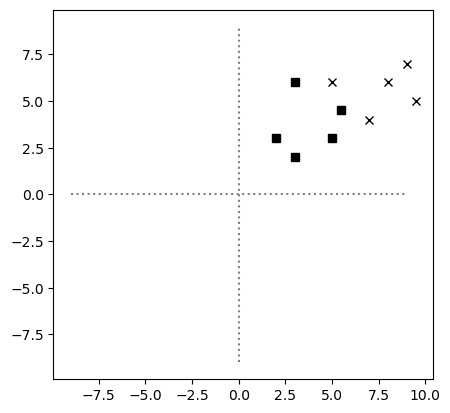

In [6]:
# dataset to be used
X = np.array([[2., 3.], [3., 2.], [3., 6.], [5.5, 4.5], [5., 3.], [7., 4.], [5., 6.], [8., 6.], [9.5, 5.], [9., 7.]])
t = np.array([0., 0., 0., 0., 0., 1., 1., 1., 1., 1.])

plot_points(X, t, plt)

Follow the methods in McKay section **41.5** to approximate the posterior distribution over the weights using a Laplace approximation and reproduce **Fig. 41.11 (b)**, which shows the Bayesian prediction $p\left(t=1|x,D,\alpha\right)$ for the target of a new input $x$.

#### Ex 2.2

Consider a Gaussian model in 1 dimension:

$$p(x|\mu,\sigma)=\frac{1}{\sqrt{2\pi}\sigma}\exp\left(-\frac{(x-\mu)^2}{2\sigma^2}\right)$$

You are given a dataset $\mathcal{D}$ composed of $N$ observations $x_n$ and tasked with finding the posterior distribution of $\mu$ and $\sigma$, assuming that $\log \sigma$ has a uniform distribution.

Introduce a factorized variational approximation $q(\mu,\beta)=q_\mu(\mu)q_\beta(\beta)$ for $p(\mu,\beta|\mathcal{D})$ and use functional derivatives to show that the KL is minimized for

$$q_\mu(\mu)=\mathcal{N}\left(\mu|\bar{x},\frac{S}{N(N-1)}\right)$$
$$q_{\beta}\left(\beta\right)=\Gamma\left(\beta|\frac{N}{2},\frac{2\left(N-1\right)}{NS}\right)$$

where $\Gamma$ is the Gamma distribution in the shape/scale parametrization and we introduced the notations $\bar{x}=\frac{1}{N}\sum_n x_n$, $S=\sum_n(x_n-\bar{x})^2$.